In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "transactions.csv"
OUTPUT_DIR = PROJECT_ROOT / "notebooks" / "outputs"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

print("Project:", PROJECT_ROOT)
print("Input dataset exists:", DATA_PATH.exists())
print("Output folder:", OUTPUT_DIR)
print("Processed data folder:", PROCESSED_DIR)

Project: c:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system
Input dataset exists: True
Output folder: c:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system\notebooks\outputs
Processed data folder: c:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system\data\processed


In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)

print("Original dataset shape:", df.shape)
display(df.head())

required_columns = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "isFraud",
]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(
        f"Expected columns are missing: {missing_columns}. "
        "Check whether your dataset is the PaySim fraud dataset "
        "or update the column names for your actual dataset."
    )

print("All required columns are present.")

Original dataset shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


All required columns are present.


In [3]:
print("Dataset shape:", df.shape)

quality_report = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(4),
    "unique_values": df.nunique(dropna=False),
})

display(quality_report)

print("Exact duplicate rows:", df.duplicated().sum())

print("\nFraud label distribution:")
display(df["isFraud"].value_counts(dropna=False))

print("\nTransaction types:")
display(df["type"].value_counts(dropna=False))

print("\nNumeric summary:")
display(df.describe().T)

Dataset shape: (6362620, 11)


,dtype,missing_count,missing_percent,unique_values
step,int64,0,0.0,743
type,str,0,0.0,5
amount,float64,0,0.0,5316900
nameOrig,str,0,0.0,6353307
oldbalanceOrg,float64,0,0.0,1845844
newbalanceOrig,float64,0,0.0,2682586
nameDest,str,0,0.0,2722362
oldbalanceDest,float64,0,0.0,3614697
newbalanceDest,float64,0,0.0,3555499
isFraud,int64,0,0.0,2


Exact duplicate rows: 0

Fraud label distribution:


isFraud
0    6354407
1       8213
Name: count, dtype: int64


Transaction types:


type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


Numeric summary:


,count,mean,std,min,25%,50%,75%,max
step,6362620.0,2.433972e+02,1.423320e+02,1.0,156.00,239.000,3.350000e+02,7.430000e+02
amount,6362620.0,1.798619e+05,6.038582e+05,0.0,13389.57,74871.940,2.087215e+05,9.244552e+07
oldbalanceOrg,6362620.0,8.338831e+05,2.888243e+06,0.0,0.00,14208.000,1.073152e+05,5.958504e+07
newbalanceOrig,6362620.0,8.551137e+05,2.924049e+06,0.0,0.00,0.000,1.442584e+05,4.958504e+07
oldbalanceDest,6362620.0,1.100702e+06,3.399180e+06,0.0,0.00,132705.665,9.430367e+05,3.560159e+08
newbalanceDest,6362620.0,1.224996e+06,3.674129e+06,0.0,0.00,214661.440,1.111909e+06,3.561793e+08
isFraud,6362620.0,1.290820e-03,3.590480e-02,0.0,0.00,0.000,0.000000e+00,1.000000e+00
isFlaggedFraud,6362620.0,2.514687e-06,1.585775e-03,0.0,0.00,0.000,0.000000e+00,1.000000e+00


In [4]:
numeric_columns = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing values in important columns:")
display(df[required_columns].isna().sum())

print("Negative transaction amounts:", (df["amount"] < 0).sum())
print("Zero transaction amounts:", (df["amount"] == 0).sum())
print("Negative step values:", (df["step"] < 0).sum())

print("\nAmount percentiles:")
display(df["amount"].quantile([0, 0.25, 0.5, 0.75, 0.90, 0.95, 0.99, 0.999, 1]))

print("\nLargest transactions:")
display(df.nlargest(10, "amount")[
    ["step", "type", "amount", "oldbalanceOrg",
     "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFraud"]
])

Missing values in important columns:


step              0
type              0
amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
dtype: int64

Negative transaction amounts: 0
Zero transaction amounts: 16
Negative step values: 0

Amount percentiles:


0.000    0.000000e+00
0.250    1.338957e+04
0.500    7.487194e+04
0.750    2.087215e+05
0.900    3.654233e+05
0.950    5.186342e+05
0.990    1.615979e+06
0.999    8.956798e+06
1.000    9.244552e+07
Name: amount, dtype: float64


Largest transactions:


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
3686583,276,TRANSFER,92445516.64,0.0,0.0,9.595980e+03,9.245511e+07,0
4060598,300,TRANSFER,73823490.36,0.0,0.0,9.362401e+07,1.674475e+08,0
4146397,303,TRANSFER,71172480.42,0.0,0.0,1.134615e+08,1.846340e+08,0
3946920,286,TRANSFER,69886731.30,0.0,0.0,1.515387e+08,2.214254e+08,0
3911956,284,TRANSFER,69337316.27,0.0,0.0,1.130072e+08,1.823446e+08,0
3937152,286,TRANSFER,67500761.29,0.0,0.0,8.635615e+07,1.538569e+08,0
4105338,302,TRANSFER,66761272.21,0.0,0.0,6.874206e+07,1.355033e+08,0
3892529,284,TRANSFER,64234448.19,0.0,0.0,6.597691e+07,1.663021e+08,0
3991638,298,TRANSFER,63847992.58,0.0,0.0,7.217149e+07,1.360195e+08,0
4143801,303,TRANSFER,63294839.63,0.0,0.0,7.512528e+07,1.384201e+08,0


In [5]:
#cleaning the data
original_rows = len(df)

duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

missing_label_count = int(df["isFraud"].isna().sum())
df = df.dropna(subset=["isFraud"]).copy()

# Fraud labels should be binary: 0 = normal, 1 = fraud.
invalid_label_mask = ~df["isFraud"].isin([0, 1])
invalid_label_count = int(invalid_label_mask.sum())
df = df.loc[~invalid_label_mask].copy()

# Keep numeric labels in a consistent format.
df["isFraud"] = df["isFraud"].astype("int8")

cleaning_report = pd.DataFrame([
    {
        "action": "Rows before cleaning",
        "rows_affected": original_rows,
        "decision": "Original input dataset"
    },
    {
        "action": "Exact duplicate rows removed",
        "rows_affected": duplicate_count,
        "decision": "Removed exact duplicate records"
    },
    {
        "action": "Rows with missing fraud label removed",
        "rows_affected": missing_label_count,
        "decision": "Cannot use unknown labels for supervised analysis"
    },
    {
        "action": "Rows with invalid fraud labels removed",
        "rows_affected": invalid_label_count,
        "decision": "Retained only labels 0 and 1"
    },
    {
        "action": "Large transaction amounts removed as outliers",
        "rows_affected": 0,
        "decision": "Kept because unusual amounts may be genuine fraud signals"
    },
])

display(cleaning_report)

print("Rows after cleaning:", len(df))
print("Shape after cleaning:", df.shape)

print("\nRemaining missing values:")
display(df.isna().sum().sort_values(ascending=False))

cleaning_report.to_csv(
    OUTPUT_DIR / "cleaning_report.csv",
    index=False
)

,action,rows_affected,decision
0,Rows before cleaning,6362620,Original input dataset
1,Exact duplicate rows removed,0,Removed exact duplicate records
2,Rows with missing fraud label removed,0,Cannot use unknown labels for supervised analysis
3,Rows with invalid fraud labels removed,0,Retained only labels 0 and 1
4,Large transaction amounts removed as outliers,0,Kept because unusual amounts may be genuine fr...


Rows after cleaning: 6362620
Shape after cleaning: (6362620, 11)

Remaining missing values:


step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [6]:
# Add temporary analysis columns.
# These will also be useful when we engineer model features later.
df["hour_of_day"] = df["step"] % 24

df["origin_emptied"] = (
    df["oldbalanceOrg"].notna()
    & df["newbalanceOrig"].eq(0)
)

df["destination_balance_zero"] = (
    df["newbalanceDest"].notna()
    & df["newbalanceDest"].eq(0)
)

print("Simulated hour range:",
      df["hour_of_day"].min(), "to", df["hour_of_day"].max())

print("Origin emptied count:", int(df["origin_emptied"].sum()))
print("Destination balance zero count:",
      int(df["destination_balance_zero"].sum()))

Simulated hour range: 0 to 23
Origin emptied count: 3609566
Destination balance zero count: 2439433


,transactions,fraud_transactions,fraud_rate,fraud_rate_percent
type,,,,
TRANSFER,532909,4097,0.007688,0.768799
CASH_OUT,2237500,4116,0.001840,0.183955
CASH_IN,1399284,0,0.000000,0.000000
DEBIT,41432,0,0.000000,0.000000
PAYMENT,2151495,0,0.000000,0.000000


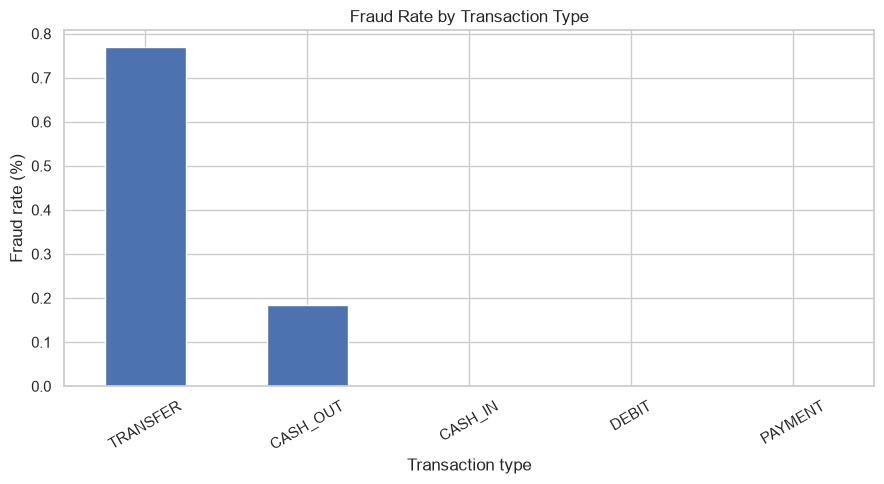

In [7]:
fraud_by_type = (
    df.groupby("type", dropna=False)
      .agg(
          transactions=("isFraud", "size"),
          fraud_transactions=("isFraud", "sum"),
          fraud_rate=("isFraud", "mean"),
      )
      .sort_values("fraud_rate", ascending=False)
)

fraud_by_type["fraud_rate_percent"] = fraud_by_type["fraud_rate"] * 100

display(fraud_by_type)

fraud_by_type["fraud_rate_percent"].plot(
    kind="bar",
    figsize=(9, 5),
    ylabel="Fraud rate (%)",
    xlabel="Transaction type",
    title="Fraud Rate by Transaction Type",
    rot=30,
)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_01_fraud_by_type.png", dpi=150)
plt.show()

fraud_by_type.to_csv(OUTPUT_DIR / "fraud_by_type.csv")

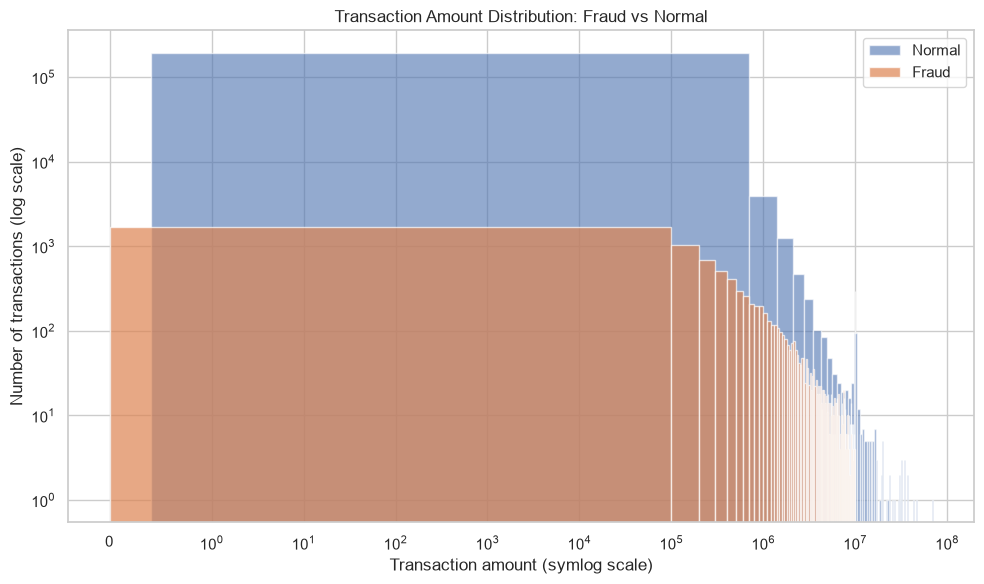

Normal transactions plotted: 200000
Fraud transactions plotted: 8213

Amount summary by fraud label:


,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,13368.395,74684.72,208364.76,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.330,441423.44,1517771.48,10000000.00


In [8]:
normal = df.loc[df["isFraud"] == 0, "amount"]
fraud = df.loc[df["isFraud"] == 1, "amount"]

# Use a reproducible sample of normal transactions for plotting,
# while keeping all fraud rows in the plot.
normal_plot = normal.sample(
    n=min(200_000, len(normal)),
    random_state=42
)

fraud_plot = fraud

plt.figure(figsize=(10, 6))

plt.hist(
    normal_plot[normal_plot >= 0],
    bins=100,
    alpha=0.6,
    label="Normal",
    log=True,
)

plt.hist(
    fraud_plot[fraud_plot >= 0],
    bins=100,
    alpha=0.7,
    label="Fraud",
    log=True,
)

plt.xscale("symlog", linthresh=1)
plt.xlabel("Transaction amount (symlog scale)")
plt.ylabel("Number of transactions (log scale)")
plt.title("Transaction Amount Distribution: Fraud vs Normal")
plt.legend()
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "eda_02_amount_distribution.png", dpi=150)
plt.show()

print("Normal transactions plotted:", len(normal_plot))
print("Fraud transactions plotted:", len(fraud_plot))

print("\nAmount summary by fraud label:")
display(df.groupby("isFraud")["amount"].describe())

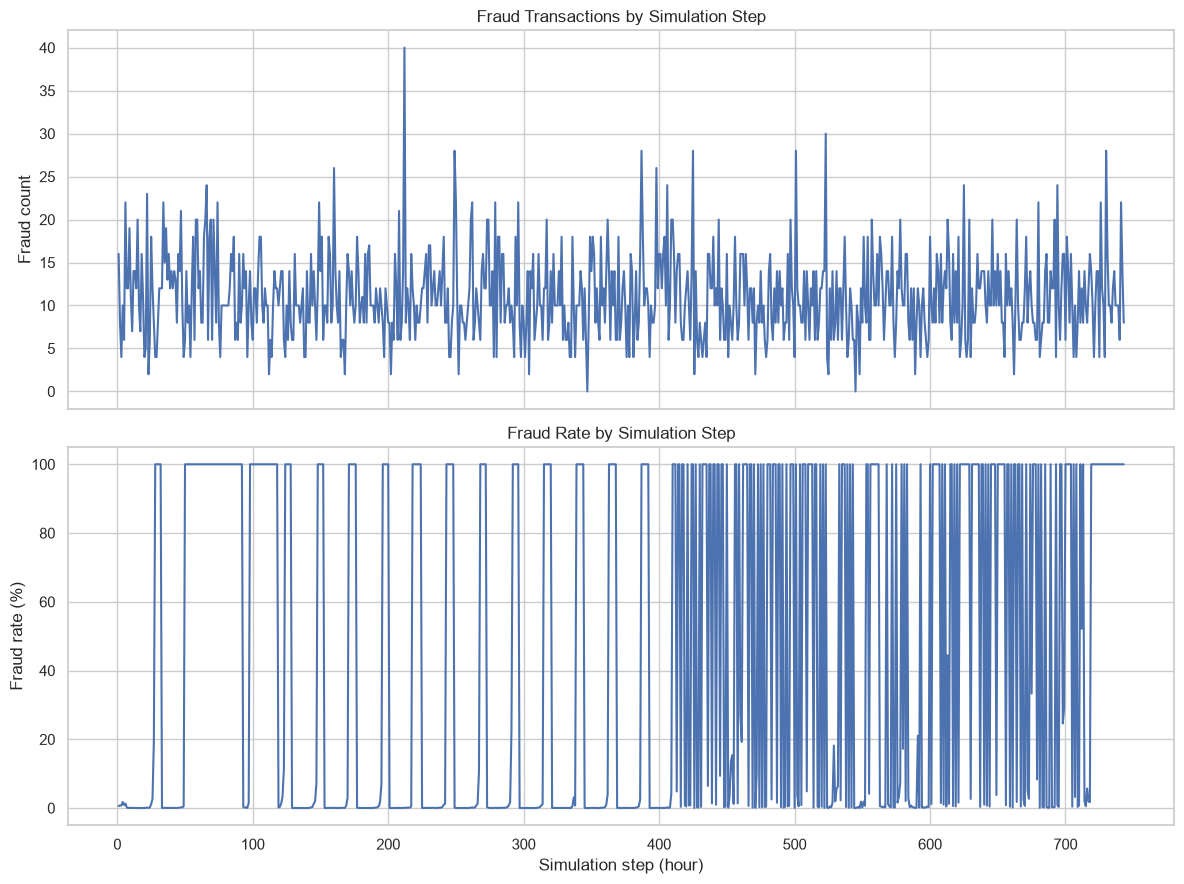

,transactions,fraud_transactions,fraud_rate,fraud_rate_percent
hour_of_day,,,,
0,71587,300,0.004191,0.419071
1,27111,358,0.013205,1.320497
2,9018,372,0.041251,4.125083
3,2007,326,0.162431,16.243149
4,1241,274,0.220790,22.078969
5,1641,366,0.223035,22.303473
6,3420,358,0.104678,10.467836
7,8988,328,0.036493,3.649310
8,26915,368,0.013673,1.367267


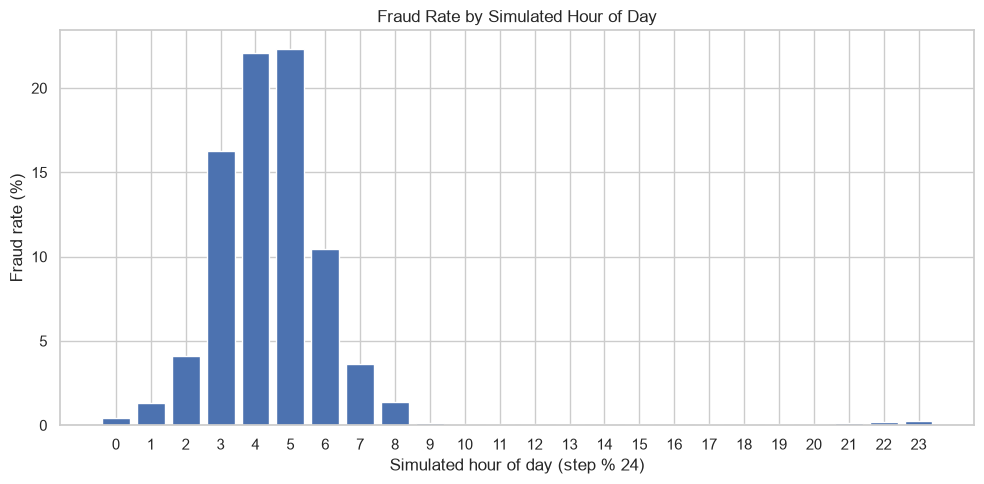

In [9]:
fraud_by_step = (
    df.groupby("step")
      .agg(
          transactions=("isFraud", "size"),
          fraud_transactions=("isFraud", "sum"),
          fraud_rate=("isFraud", "mean"),
      )
)

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

axes[0].plot(
    fraud_by_step.index,
    fraud_by_step["fraud_transactions"],
)
axes[0].set_title("Fraud Transactions by Simulation Step")
axes[0].set_ylabel("Fraud count")

axes[1].plot(
    fraud_by_step.index,
    fraud_by_step["fraud_rate"] * 100,
)
axes[1].set_title("Fraud Rate by Simulation Step")
axes[1].set_xlabel("Simulation step (hour)")
axes[1].set_ylabel("Fraud rate (%)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_03_fraud_by_step.png", dpi=150)
plt.show()

fraud_by_hour = (
    df.groupby("hour_of_day")
      .agg(
          transactions=("isFraud", "size"),
          fraud_transactions=("isFraud", "sum"),
          fraud_rate=("isFraud", "mean"),
      )
)

fraud_by_hour["fraud_rate_percent"] = fraud_by_hour["fraud_rate"] * 100

display(fraud_by_hour)

plt.figure(figsize=(10, 5))
plt.bar(
    fraud_by_hour.index,
    fraud_by_hour["fraud_rate_percent"],
)
plt.xticks(range(24))
plt.xlabel("Simulated hour of day (step % 24)")
plt.ylabel("Fraud rate (%)")
plt.title("Fraud Rate by Simulated Hour of Day")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "eda_03_fraud_by_hour.png", dpi=150)
plt.show()

fraud_by_step.to_csv(OUTPUT_DIR / "fraud_by_step.csv")
fraud_by_hour.to_csv(OUTPUT_DIR / "fraud_by_hour.csv")

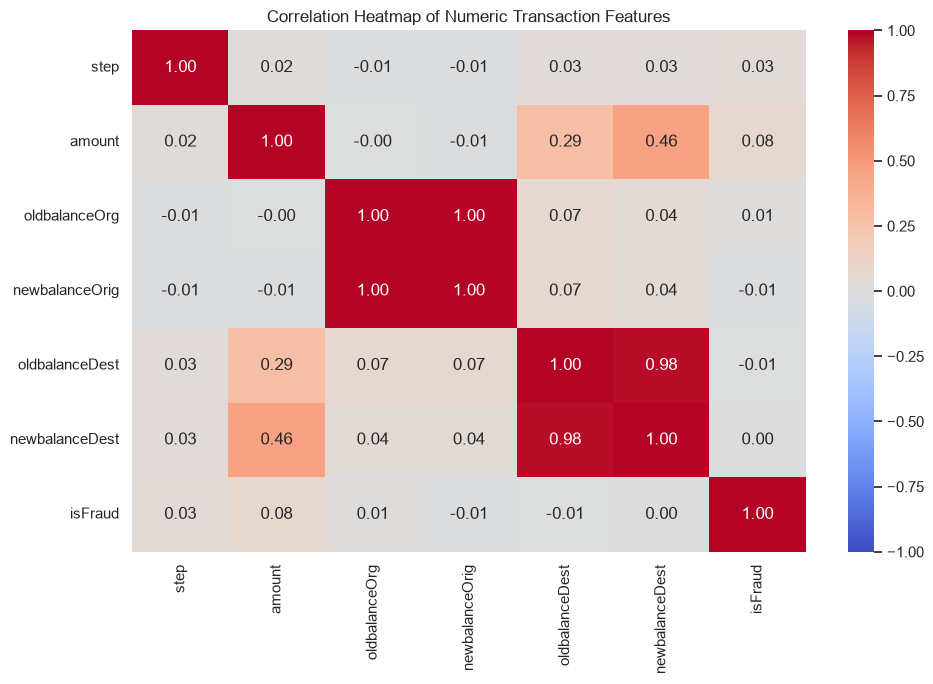

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
step,1.000000,0.022373,-0.010058,-0.010299,0.027665,0.025888,0.031578
amount,0.022373,1.000000,-0.002762,-0.007861,0.294137,0.459304,0.076688
oldbalanceOrg,-0.010058,-0.002762,1.000000,0.998803,0.066243,0.042029,0.010154
newbalanceOrig,-0.010299,-0.007861,0.998803,1.000000,0.067812,0.041837,-0.008148
oldbalanceDest,0.027665,0.294137,0.066243,0.067812,1.000000,0.976569,-0.005885
newbalanceDest,0.025888,0.459304,0.042029,0.041837,0.976569,1.000000,0.000535
isFraud,0.031578,0.076688,0.010154,-0.008148,-0.005885,0.000535,1.000000


In [10]:
correlation_columns = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "isFraud",
]

correlation_data = df[correlation_columns].copy()
correlation_matrix = correlation_data.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)

plt.title("Correlation Heatmap of Numeric Transaction Features")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "eda_04_correlation_heatmap.png", dpi=150)
plt.show()

display(correlation_matrix)
correlation_matrix.to_csv(OUTPUT_DIR / "correlation_matrix.csv")

Fraud rate by whether the origin balance is zero:


,transactions,fraud_transactions,fraud_rate,fraud_rate_percent
origin_emptied,,,,
False,2753054,160,0.000058,0.005812
True,3609566,8053,0.002231,0.223102


Fraud rate by whether the destination balance is zero:


,transactions,fraud_transactions,fraud_rate,fraud_rate_percent
destination_balance_zero,,,,
False,3923187,4122,0.001051,0.105068
True,2439433,4091,0.001677,0.167703


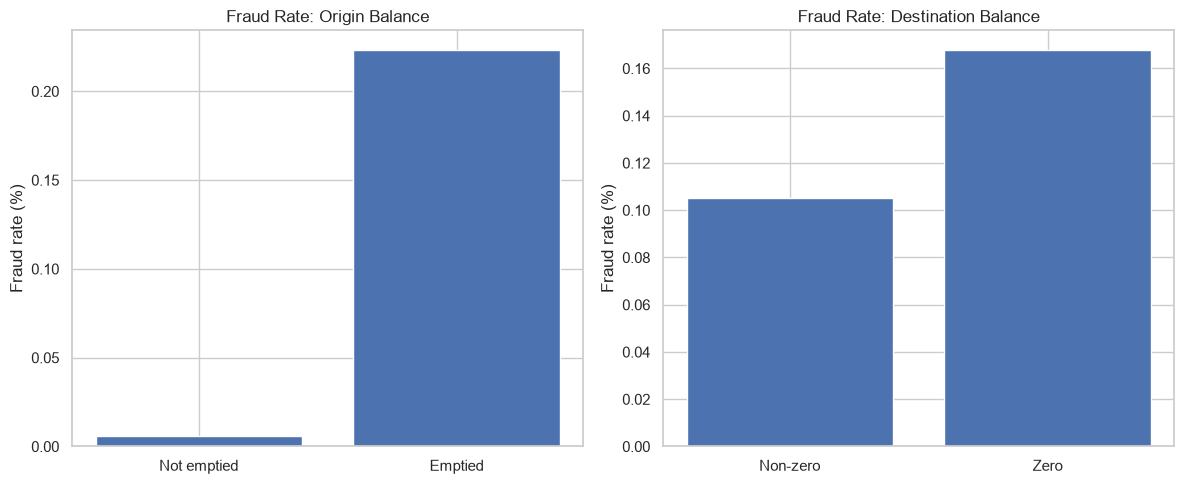

In [11]:
origin_pattern = (
    df.groupby("origin_emptied")
      .agg(
          transactions=("isFraud", "size"),
          fraud_transactions=("isFraud", "sum"),
          fraud_rate=("isFraud", "mean"),
      )
)

origin_pattern["fraud_rate_percent"] = origin_pattern["fraud_rate"] * 100

print("Fraud rate by whether the origin balance is zero:")
display(origin_pattern)

destination_pattern = (
    df.groupby("destination_balance_zero")
      .agg(
          transactions=("isFraud", "size"),
          fraud_transactions=("isFraud", "sum"),
          fraud_rate=("isFraud", "mean"),
      )
)

destination_pattern["fraud_rate_percent"] = (
    destination_pattern["fraud_rate"] * 100
)

print("Fraud rate by whether the destination balance is zero:")
display(destination_pattern)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(
    ["Not emptied", "Emptied"],
    [
        origin_pattern["fraud_rate_percent"].get(False, 0),
        origin_pattern["fraud_rate_percent"].get(True, 0),
    ],
)
axes[0].set_title("Fraud Rate: Origin Balance")
axes[0].set_ylabel("Fraud rate (%)")

axes[1].bar(
    ["Non-zero", "Zero"],
    [
        destination_pattern["fraud_rate_percent"].get(False, 0),
        destination_pattern["fraud_rate_percent"].get(True, 0),
    ],
)
axes[1].set_title("Fraud Rate: Destination Balance")
axes[1].set_ylabel("Fraud rate (%)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_05_balance_zeroing.png", dpi=150)
plt.show()

origin_pattern.to_csv(OUTPUT_DIR / "origin_balance_zeroing.csv")
destination_pattern.to_csv(
    OUTPUT_DIR / "destination_balance_zeroing.csv"
)

In [12]:
CLEANED_PATH = PROCESSED_DIR / "transactions_cleaned.csv.gz"

df.to_csv(
    CLEANED_PATH,
    index=False,
    compression="gzip",
)

print("Cleaned dataset saved to:", CLEANED_PATH)
print("Final cleaned shape:", df.shape)
print("File size (MB):", round(CLEANED_PATH.stat().st_size / (1024**2), 2))

Cleaned dataset saved to: c:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system\data\processed\transactions_cleaned.csv.gz
Final cleaned shape: (6362620, 14)
File size (MB): 180.21


In [13]:
print("PHASE 1 — NOTEBOOK 02 SUMMARY")
print("-" * 40)

print("Final rows:", len(df))
print("Final columns:", len(df.columns))
print("Remaining duplicate rows:", df.duplicated().sum())
print("Missing fraud labels:", df["isFraud"].isna().sum())
print("Fraud transactions:", int((df["isFraud"] == 1).sum()))
print("Normal transactions:", int((df["isFraud"] == 0).sum()))

print("\nRemaining missing values:")
display(df.isna().sum().sort_values(ascending=False).head(15))

print("\nEDA output files:")
for path in sorted(OUTPUT_DIR.glob("eda_*.png")):
    print("-", path.name)

print("\nCleaning report exists:", (OUTPUT_DIR / "cleaning_report.csv").exists())
print("Cleaned dataset exists:", CLEANED_PATH.exists())

PHASE 1 — NOTEBOOK 02 SUMMARY
----------------------------------------
Final rows: 6362620
Final columns: 14
Remaining duplicate rows: 0
Missing fraud labels: 0
Fraud transactions: 8213
Normal transactions: 6354407

Remaining missing values:


step                        0
type                        0
amount                      0
nameOrig                    0
oldbalanceOrg               0
newbalanceOrig              0
nameDest                    0
oldbalanceDest              0
newbalanceDest              0
isFraud                     0
isFlaggedFraud              0
hour_of_day                 0
origin_emptied              0
destination_balance_zero    0
dtype: int64


EDA output files:
- eda_01_fraud_by_type.png
- eda_02_amount_distribution.png
- eda_03_fraud_by_hour.png
- eda_03_fraud_by_step.png
- eda_04_correlation_heatmap.png
- eda_05_balance_zeroing.png

Cleaning report exists: True
Cleaned dataset exists: True
